In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import pandas as pd 

# Übungsblatt 1 in Mechanistische Effektmodellierung 2026: GUTS

### Hinweis:
Entpacken Sie die auf Vips bereitgestellte zip-Datei in dem Ordner, in dem sich dieses Notebook befindet.

## Aufgabe 1: TK-Modell

Eins der einfachsten TK-Modelle, das auch für Full-GUTS verwendet wird, ist das Diffusionsmodell zwischen zwei Phasen:
$$
\frac{dC_i}{dt} = k_e \left( K_{iw}C_W  - C_i \right)
$$

$C_i$ beschreibt die interne Konzentration und $C_W$ die externe Koncentration. <br>

Der Verteilungskoeffizient zwischen Organismus und Wasser ($K_{iw}$) wird oft als Biokonzentrationsfaktor bezeichnet (siehe MKS/Angleichungsmodul).


Die Ratenkonstante $k_e$ beeinflusst sowohl Eliminierung als auch, zusammen mit $K_{iw}$, die Aufnahme der Substanz. <br>
Am besten betrachtet man $k_e$ als Ratenkonstante, die die Equilibrierungsgeschwindikeit zwischen Organismus und Medium bestimmt.

### A1a  
Implementieren Sie das beschriebene Modell in Python und simulieren Sie über 40 Zeiteinheiten. Plotten Sie den Verlauf von $C_i$ über der Zeit mit den folgenden Parameterwerten.

In [28]:
p = {
    'k_e' : 0.2,
    'K_iw' : 1,
    'C_W' : 1
}

Text(0.5, 1.0, 'C_i over time')

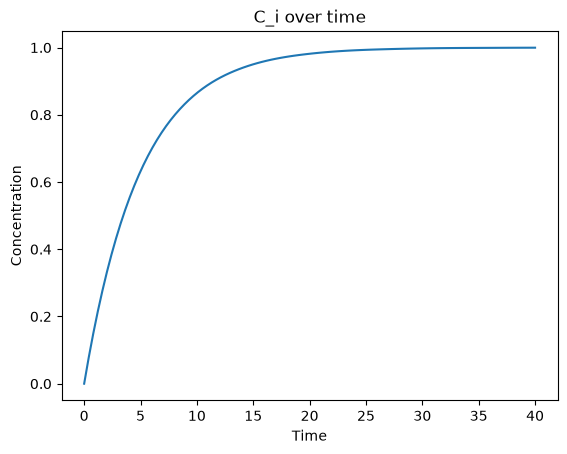

In [29]:
# Lösung
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def tk_model(t,y, p):
    C_i = y[0]
    dC_i_dt = p['k_e'] * (p['C_W']*p['K_iw'] - C_i)
    return [dC_i_dt]

C_i = solve_ivp(tk_model, [0, 40], [0], args=(p,), dense_output=True)

plt.figure()
t = np.linspace(0, 40, 100)
plt.plot(t, C_i.sol(t)[0], label='C_i(t)')
plt.xlabel('Time')
plt.ylabel('Concentration')
plt.title('C_i over time')

Bisher haben wir $C_w$ als konstant angenommen. Wenn $C_w$ nicht konstant ist liegen meistens nur ein paar wenige Messungen der Konzentration im Wasser vor. Um zeitkontinuirlich zu simulieren wird jedoch für jeden möglichen Zeitpunkt ein Wert benötigt: Wir müssen $C_w$ interpolieren. 

### A1b
In der folgenden CSV-Datei sind 3 Expositionsszenarien gegeben, für die zu jeweils 3 Zeitpunkten die Konzentration im Wasser $C_w$ gegeben ist. Interpolieren Sie die gegebenen Werte linear, plotten Sie den resultierenden Verlauf von $C_w$ über der Zeit. Simulieren Sie im Anschluss das simple TK-Modell für alle 3 Szenarien über 50 Zeiteinheiten und plotten Sie alle 3 sich ergebenden Zeitverläufe von $C_i$ in einem einzelnen weiteren plot.

In [30]:
from scipy.interpolate import interp1d
import pandas as pd
# https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.interp1d.html

exposures = pd.read_csv("data/TK_exposure_scenarios_01.csv")
exposures

,scenario,t,C_W
0,1,0,0.10
1,1,30,0.10
2,1,50,0.00
3,2,0,0.25
4,2,30,0.25
5,2,50,0.00
6,3,0,0.50
7,3,30,0.50
8,3,50,0.00


<Figure size 640x480 with 0 Axes>

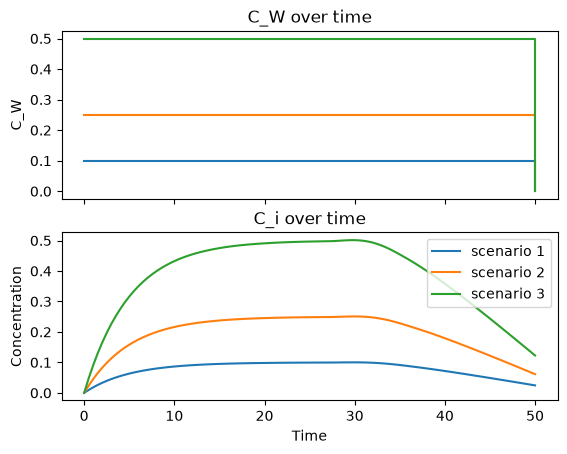

In [60]:
# Lösung
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy import interpolate
p = {
    'k_e' : 0.2,
    'K_iw' : 1
}

def tk_model(t,y, p,C_w):
    C_i = y[0]
    dC_i_dt = p['k_e'] * (C_w(t) * p['K_iw'] - C_i)
    return [dC_i_dt] 

plt.figure()
fig, ax = plt.subplots(2, 1, sharex=True)

for i in range(3):
    ex_sceni = exposures[exposures['scenario'] == i+1]
    C_w = interpolate.interp1d(ex_sceni['t'], ex_sceni['C_W'], fill_value="extrapolate")

    ax[0].step(ex_sceni["t"], ex_sceni["C_W"], where="post")

    C_i = solve_ivp(tk_model, [0, 50], [0], args=(p,C_w), dense_output=True)
    ax[1].plot(np.linspace(0, 50, 100), C_i.sol(np.linspace(0, 50, 100))[0], label='scenario {}'.format(i+1))

ax[0].set_ylabel('C_W')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('C_i')

plt.ylabel('Concentration')
ax[0].set_title('C_W over time')
ax[1].set_title('C_i over time')
plt.legend()
plt.show()


### A1c

Ändern Sie die Interpolationsmethode von linear zu stufenförmig und wiederholen Sie die Simulationen. Nehmen Sie Stellung zur Relevanz der Wahl der Interpolationsmethode für das Ergebnis. Worauf sollte in der Anwendung geachtet werden? Unter welchen Umständen würden sie welche der beiden Methoden verwenden? Begründen Sie.

<Figure size 640x480 with 0 Axes>

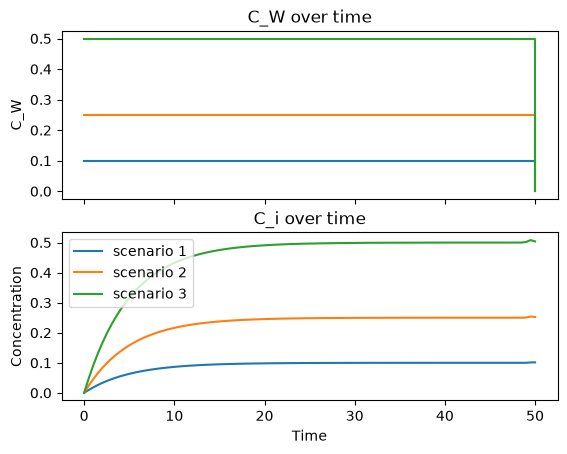

In [63]:

# Lösung
plt.figure()
fig, ax = plt.subplots(2, 1, sharex=True)
for i in range(3):
    ex_sceni = exposures[exposures['scenario'] == i+1]
    C_w = interpolate.interp1d(ex_sceni['t'], ex_sceni['C_W'],kind="previous",fill_value="extrapolate")
    
    ax[0].step(ex_sceni["t"], ex_sceni["C_W"], where="post")

    C_i = solve_ivp(tk_model, [0, 60], [0], args=(p,C_w), dense_output=True)
    
    ax[1].plot(np.linspace(0, 50, 100), C_i.sol(np.linspace(0, 50, 100))[0], label='scenario {}'.format(i+1))
    

ax[0].set_ylabel('C_W')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('C_i')

plt.ylabel('Concentration')
ax[0].set_title('C_W over time')
ax[1].set_title('C_i over time')
plt.legend()
plt.show()


Antwort:  
Die wahl der Interpolationsmethode verändert die Ergebnisse drastisch, weil wir damit den Zeitpunkten für die wir keine Messung haben einen Wert zuschreiben. Das verkörpert eine zusätzliche Annahme mit der wir das Modell füttern. Es ist in der Anwendung wichtig, zu prüfen welche Annahme plausibel für das untersuchte System ist.

linear wenn die externe konzentration tatsählich linear verwässert wird.

Stufenweise wenn der untersuchte Organismus in ein anderes Gewässer gesteckt wird. 

Es sind natürlich auch deutlich komplexere Expositionsprofile möglich. FOCUS-Expositionsprofile (FOrum for the Co-ordination of pesticide fate models and their USe) sind standardisierte Simulationsmodelle und Szenarien, die von der Europäischen Behörde für Lebensmittelsicherheit (EFSA) genutzt werden. 

### A1d
Die Datei `data/profile_focus.csv` enthält ein solches Expositionsprofil. Importieren Sie es und simulieren Sie das TK-Modell unter Annahme dieses Szenarios und linearer Interpolation. Plotten sie wie bisher $C_w$ und $C_i$ im Zeitverlauf.

In [64]:
focus_exposures = pd.read_csv("data/profile_focus.csv")
focus_exposures

,t,C_W
0,0.000,0.00000
1,0.042,0.00003
2,0.083,0.00006
3,0.125,0.00009
4,0.167,0.00012
...,...,...
11636,484.833,0.00002
11637,484.875,0.00002
11638,484.917,0.00002
11639,484.958,0.00002


<Figure size 640x480 with 0 Axes>

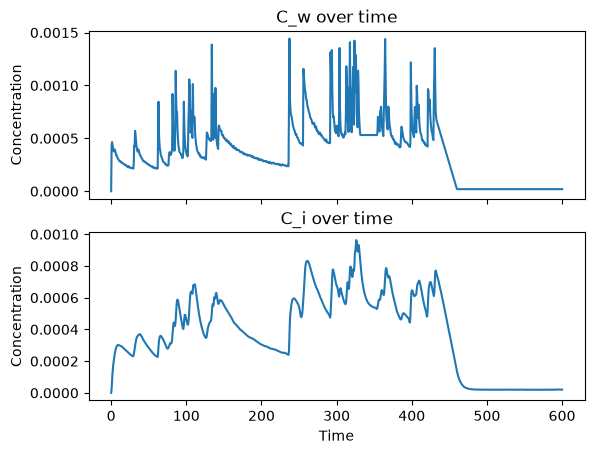

In [100]:
# Lösung

plt.figure()
fig, ax = plt.subplots(2, 1, sharex=True)

C_w = interpolate.interp1d(focus_exposures['t'], focus_exposures['C_W'], fill_value="extrapolate")
# plot C_w via C_w(t)
ax[0].plot(np.linspace(0, 600, 1000), C_w(np.linspace(0, 600, 1000)))
#plt.plot(ex_sceni['t'], ex_sceni['C_W'], label='C_w(t) scenario {}'.format(i+1))
C_i = solve_ivp(tk_model, [0, 600], [0], args=(p,C_w), dense_output=True)
ax[1].plot(np.linspace(0, 600, 1000), C_i.sol(np.linspace(0, 600, 1000))[0])

ax[1].set_xlabel('Time')
#plt.yscale('log')
#plt.xscale('log')
ax[0].set_ylabel('Concentration')
ax[1].set_ylabel('Concentration')
ax[0].set_title('C_w over time')
ax[1].set_title('C_i over time')

plt.show()

## Aufgabe 2: GUTS-Reduced
Bearbeiten Sie nun einen Datensatz, der am UFZ in Leipzig erstellt wurde mithilfe von GUTS-Modellen. In der Untersuchung ging es um die Hypothese, dass UV-B Strahlung die Wirkung des Pestizids Esfenvalerat verstärkt. Bevor wir uns mit der Wirkung der Interaktion des Pestizids beschäftigen, schauen wir uns die Exposition mit UV-B Strahlung genauer an. UV-B Strahlung verursacht DNA Schäden und ROS (reactive oxygen species), welche oxidativen Stress auf Zellmembranen, Proteine und DNA ausüben. Sie wird hier als Bestrahlungsstärke in der Einheit $mW*cm^{-2}$ angegeben.

<i>
Hinweis:  
  
Du kannst mempy mit dem folgenden command in dein conda environment installieren:  
</i>
<code>
pip install "mempyguts[pymob] @ git+https://gitlab.uni-osnabrueck.de/memuos/mempyguts.git@61-mempy-fit-not-compatible-with-some-models"
</code>

In [ ]:
import mempy
from mempy.model import RED_SD

In [ ]:
exposure_funcs, survival_data, num_expos = mempy.input_data.read_exposure_survival(
    "data/uvb_esfenvalerate/uv/", "openguts_survival.xlsx", 
    exposure_name="uv",
    survival_name="survival",
    info_name="meta",
    visualize=True
)

### A2a
Wir betrachten hier keine Chemikalie sondern einen andersartigen Stressor: UV-B-Strahlung. Überlegen Sie ob diese Nutzung von GUTS-RED konzeptionell zulässig ist oder nicht und argumentieren Sie. Könnte man auch Full-GUTS für die Modellierung verwenden? Begründen Sie und notieren Sie ihre Gedanken.

Antwort:

### A2b
Rufen Sie sich die Funktionsweise des GUTS-RED-SD-Modells in Erinnerung und die Bedeutung seiner Parameter. Versuchen Sie die mit dem GUTS-RED-SD-Modell simulierten Survival Kurven an die Daten anzupassen, indem sie die Parameter manuell verändern.

In [ ]:
modelsd = RED_SD()

In [ ]:
# Lösung

params = {
    "hb": 99, 
    "kd": 99, 
    "m":  99, 
    "b":  99, 
}


modelsd.plot(
    params=params,
    exposure_funcs=exposure_funcs,
    observed_data=survival_data
)

### A2c
Benutzen sie den Nelder-Mead Algorithmus von mempyguts um das SD Modell an die Daten anzupassen.

Nehmen Sie Stellung zur Modellgüte. Spiegelt das GUTS-RED-SD-Modell mit den durch den Nelder-Mead-Algorithmus inferierten Parameterwerten das beobachtete Survival angemessen wieder? Ab welcher Expositionsdauer (welchem Szenario) sagt das Modell einen signifikanten Einfluss des Stressors auf das Überleben vorher? Begründen Sie.

In [ ]:
# Lösung

Antwort:

### A2d

Berechnen Sie den LP50 für alle Expositionsprofile. Erstellen Sie eine Abbildung in der sie den LP50 über die Expositionsdauer mit $15 mW*cm^{-2}$ UV-Strahlung darstellen. Was beobachten Sie? Was sagt der LP50 aus?

<i>Hinweise:  
  
Setzten Sie das 'visualize' argument der LP_X Methode auf False, wenn Sie nicht mit 9 großen Plots konfrontiert werden wollen.  
  
Die interpolierten Expositionsobjekte in exposure_funcs[uv]["Szenario"] haben eine Methode get_knots(), welche die Zeitpunkte der Rohdaten zurückgibt und eine Methode get_coeffs(), welche die y-Werte der Rohdaten zurückgibt. Damit können Sie die Zeiten bestimmen, an denen die jeweiligen Expositionen enden.</i>

In [ ]:
# Lösung

Antwort:

### A2e
Fitten sie auch das GUTS-RED-IT-Modell an die Daten. Schätzen Sie auch hier kurz die Modellgüte ein und beschreiben Sie Gemeinsamkeiten und Unterschiede in den Modellvorhersagen. Erklären Sie, wie die Form der Survival-Kurven zustande kommt; Warum nimmt das Survival bei längeren Expositionsdauern so plötzlich ab und nach Ende der Exposition nur langsam?

In [ ]:
# Lösung

Antwort:

## Augabe 3: GUTS-Mixtures

Gemische von Chemikalien sind ein sehr realer Bestandteil der Umwelt und sie Stellen sowohl Tiere als auch Menschen vor Herausforderungen. Die Anzahl der aktuell kommerziell gehandelten Chemikalien liegt bei 50,000. Nimmt man alle Chemikalien hinzu die in der Vergangenheit gehandelt werden sind wir bei 350,000 Substanzen. Diese Menge kann auf Organismen in unterschiedlichen Konzentrationen wirken. Bisher haben wir uns nur mit der Wirkung einer Substanz (bzw. eines Stressors UV-B Strahlung beschäftigt). Zu den Chemikalen kommen nämlich noch natürliche Stressoren hinzu.  
  
Die folgenden Daten sind das Ergebnis von Versuchen mit den beiden Stressoren in Isolation. Die Treatments "UV5 01" - "UV5 09" sind die selben, die in Aufgaben 2 verwendet wurden, also nur Exposition zu UV-B Strahlung. Die Treatments "UVP5 01" - "UVP2 01" beinhaltet eine reine Exposition mit Esfenvalerate ohne UV-B-Strahlung.

In [ ]:
exposure_funcs_calibration_mix, survival_data_calibration_mix, num_expos_calibration_mix = mempy.input_data.read_exposure_survival(
    "data/uvb_esfenvalerate/mix/", "openguts_survival.xlsx", 
    exposure_name="exposure_",
    survival_name="survival",
    info_name="meta",
    visualize=False
)

### A3a
Warum kalibriert man die Modelle an Experimente mit den isolierten Stressoren und nicht an die Mischung?

Antwort:

### A3b
Kalibrieren Sie das GUTS-RED-SD-DA (Damage Addition) Modell an die gegebenen Daten mit Hilfe des Nelder-Mead-Simplex Algorithmus aus mempy. Schätzen Sie zunächst kurz den Fit des Modells an seine Trainingsdaten ein. Beschreiben Sie Unterschiede der Vorhersage für die Zeitreihen mit reiner Exposition mit UV-B-Strahlung zu Aufgabe 2.

In [ ]:
# Lösung

Antwort:

Um zu sehen ob das Modell nun tatsächlich auch die Mischungstoxizität vorhersagen kann müssen wir die kalibrierten Parameterwerte mit tatsächlicher Exposition an die Mischung der Stressoren simulieren und nicht wie bisher nur die isolierten Stressoren. Dafür gibt es einen Validierungsdatensatz in dem die Stressoren gemeinsam getestet wurden.

### A3c

Simulieren Sie das GUTS-RED-SD-DA Modell mit den kalibrierten Parametern unter der hier importierten gleichzeitigen Exposition mit Esfenvalerate und UV-B-Strahlung. Plotten Sie die Modellvorhersage und die beobachteten Überlebensdaten zusammen und berechnen Sie den NRMSE. Schätzen Sie kurz die Vorhersagekraft des Modells für die Validierungsdaten ein. Beschreiben Sie die Überschätzung der Mortalität in den Treatments "UVP5 07" bis "UVP9 11" und erklären Sie wie diese zustandekommt. Argumentieren Sie unter Einbeziehung der Kalibrierungsergebnisse und überlegen Sie wie man diese Überschätzung biologisch/chemisch erklären könnte.

In [ ]:
exposure_funcs_validation_mix, survival_data_validation_mix, num_expos_validation_mix = mempy.input_data.read_exposure_survival(
    "data/uvb_esfenvalerate/2020_03_UVP_pulse_5/", "openguts_survival.xlsx", 
    exposure_name="exposure_",
    survival_name="survival",
    info_name="meta",
    visualize= False
)

In [ ]:
# Lösung

Antwort: